In [1]:
# Install dependencies (run once)
!pip install transformers datasets torch scikit-learn pandas matplotlib seaborn accelerate sentencepiece -q

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import set_seed

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)
from sklearn.utils.class_weight import compute_class_weight
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)

In [4]:
# ── Config ───────────────────────────────────────────────────
DATA_PATH = "/content/drive/MyDrive/conversation_en.json"

MAX_LEN = 256
VALID_LABELS = ["Chitchat", "Interpret", "Reveal", "Revise", "Inquire"]

label2id = {"Chitchat": 0, "Interpret": 1, "Reveal": 2, "Revise": 3, "Inquire": 4}
id2label = {v: k for k, v in label2id.items()}

RANDOM_STATE = 42
TEST_SIZE = 0.20
VAL_SIZE_WITHIN_TRAIN = 0.20

print("Config loaded.")
print("label2id:", label2id)
print("Using original JSON only for splits and context.")

Config loaded.
label2id: {'Chitchat': 0, 'Interpret': 1, 'Reveal': 2, 'Revise': 3, 'Inquire': 4}
Using original JSON only for splits and context.


In [5]:
# ── Load original JSON and create full-turn + target-turn dataframes ──────
with open(DATA_PATH, "r", encoding="utf-8") as f:
    raw = json.load(f)

all_rows = []
for conv in raw:
    conv_id = str(conv.get("conv_id"))
    for i, t in enumerate(conv.get("conversation", [])):
        all_rows.append({
            "conversation_id": conv_id,
            "turn_index": int(i),
            "role": str(t.get("role", "")).lower(),
            "text": t.get("content") or "",
            "intent": t.get("intent"),
        })

df_turns_full = pd.DataFrame(all_rows).sort_values(
    ["conversation_id", "turn_index"]
).reset_index(drop=True)

for col in ["conversation_id", "role", "text"]:
    df_turns_full[col] = df_turns_full[col].astype(str)
df_turns_full["turn_index"] = df_turns_full["turn_index"].astype(int)
df_turns_full["role"] = df_turns_full["role"].str.lower()
df_turns_full["text"] = df_turns_full["text"].fillna("")

# Only labeled user turns are prediction targets
target_df = df_turns_full[
    (df_turns_full["role"] == "user") &
    (df_turns_full["intent"].notna()) &
    (df_turns_full["intent"].isin(VALID_LABELS))
].copy().reset_index(drop=True)

# Full conversation lookup for context reconstruction
turns_by_conv_full = {
    cid: g.sort_values("turn_index").reset_index(drop=True)
    for cid, g in df_turns_full.groupby("conversation_id")
}

print("Full turn rows (all roles):", len(df_turns_full))
print("Target user-turn rows:", len(target_df))
print("Unique conversations:", df_turns_full["conversation_id"].nunique())
print(target_df[["conversation_id", "turn_index", "role", "intent"]].head())

Full turn rows (all roles): 5633
Target user-turn rows: 3196
Unique conversations: 826
  conversation_id  turn_index  role     intent
0          100204           0  user     Reveal
1          100204           2  user     Reveal
2          100325           0  user   Chitchat
3          100325           2  user     Reveal
4          100325           4  user  Interpret


In [6]:
from sklearn.model_selection import GroupShuffleSplit

# Step 1: Train+Val vs Test
gss1 = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
train_val_idx, test_idx = next(
    gss1.split(target_df, groups=target_df["conversation_id"])
)

train_val_df = target_df.iloc[train_val_idx].reset_index(drop=True)
test_df = target_df.iloc[test_idx].reset_index(drop=True)

# Step 2: Train vs Val
gss2 = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE_WITHIN_TRAIN, random_state=RANDOM_STATE)
train_idx, val_idx = next(
    gss2.split(train_val_df, groups=train_val_df["conversation_id"])
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)

print("Train:", len(train_df))
print("Val  :", len(val_df))
print("Test :", len(test_df))

Train: 2022
Val  : 522
Test : 652


In [7]:
# ── Context builder ────────────────────────────────────────────
def build_context_dataset(df_split, turns_by_conv):
    """
    Build one input per labeled user turn.
    Context = all previous turns in the same conversation (user + system)
    + current user turn.
    """
    X, y = [], []

    for _, row in df_split.iterrows():
        cid = row["conversation_id"]
        ti = int(row["turn_index"])

        conv_turns = turns_by_conv[cid]
        prev_turns = conv_turns[conv_turns["turn_index"] < ti]

        history = []
        for _, p in prev_turns.iterrows():
            role = str(p["role"]).upper().strip()
            text = str(p["text"]).strip()
            if text:
                history.append(f"{role}: {text}")

        current_turn = str(row["text"]).strip()

        if history:
            full_text = "\n".join(history) + "\n" + f"USER: {current_turn}"
        else:
            full_text = f"USER: {current_turn}"

        X.append(full_text)
        y.append(row["intent"])

    return np.array(X), np.array(y)


X_train, y_train = build_context_dataset(train_df, turns_by_conv_full)
X_val, y_val = build_context_dataset(val_df, turns_by_conv_full)
X_test, y_test = build_context_dataset(test_df, turns_by_conv_full)

print("Context-aware train size:", len(X_train))
print("Context-aware val size  :", len(X_val))
print("Context-aware test size :", len(X_test))

print("\nTrain distribution:")
print(pd.Series(y_train).value_counts())

print("\nVal distribution:")
print(pd.Series(y_val).value_counts())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts())

# Optional sanity check
revise_indices = [i for i, l in enumerate(y_train) if l == "Revise"]
if revise_indices:
    print("\n--- Sample Revise context (verify SYSTEM turn is present) ---")
    for line in X_train[revise_indices[0]].split("\n"):
        print(" ", line[:110])

Context-aware train size: 2022
Context-aware val size  : 522
Context-aware test size : 652

Train distribution:
Interpret    1131
Reveal        670
Chitchat      168
Revise         45
Inquire         8
Name: count, dtype: int64

Val distribution:
Interpret    304
Reveal       168
Chitchat      36
Revise        10
Inquire        4
Name: count, dtype: int64

Test distribution:
Interpret    378
Reveal       193
Chitchat      64
Revise        12
Inquire        5
Name: count, dtype: int64

--- Sample Revise context (verify SYSTEM turn is present) ---
  USER: hello，I want buy a mug
  SYSTEM: how about these？
  USER: ok,the first one i will choose.


In [8]:
cols = ["conversation_id", "turn_index", "role", "text", "intent"]

print("\n--- TRAIN HEAD ---")
print(train_df[cols].head(5))

print("\n--- VAL HEAD ---")
print(val_df[cols].head(5))

print("\n--- TEST HEAD ---")
print(test_df[cols].head(5))


--- TRAIN HEAD ---
  conversation_id  turn_index  role                          text     intent
0          100204           0  user  Hello, I want a Cotton mops.     Reveal
1          100204           2  user                OK, I find it.     Reveal
2          100325           0  user                how r u doing?   Chitchat
3          100325           2  user                 I wanna book!     Reveal
4          100325           4  user                       what!!!  Interpret

--- VAL HEAD ---
  conversation_id  turn_index  role                     text     intent
0          100698           0  user                      hi!   Chitchat
1          100698           2  user         I wanna a plane.  Interpret
2          100698           4  user                     yes!  Interpret
3          100698           6  user   the first one is good!  Interpret
4          101020           0  user  I want to buy a bicycle     Reveal

--- TEST HEAD ---
  conversation_id  turn_index  role              

In [9]:
print(X_train[1])

USER: Hello, I want a Cotton mops.
SYSTEM: Do you find these two satisfactory?
USER: OK, I find it.


In [10]:
# ── Encode labels ────────────────────────────────────────────
y_train_ids = np.array([label2id[l] for l in y_train])
y_val_ids   = np.array([label2id[l] for l in y_val])
y_test_ids  = np.array([label2id[l] for l in y_test])

train_dist = pd.Series(y_train).value_counts(normalize=True)
val_dist   = pd.Series(y_val).value_counts(normalize=True)
test_dist  = pd.Series(y_test).value_counts(normalize=True)

dist_df = pd.DataFrame({
    "train_%": train_dist,
    "val_%": val_dist,
    "test_%": test_dist
}).fillna(0)

print("Label distribution (%):")
print(dist_df)

Label distribution (%):
            train_%     val_%    test_%
Interpret  0.559347  0.582375  0.579755
Reveal     0.331355  0.321839  0.296012
Chitchat   0.083086  0.068966  0.098160
Revise     0.022255  0.019157  0.018405
Inquire    0.003956  0.007663  0.007669


In [11]:
# ── Class weights (balanced) ─────────────────────────────────
# Compute weights only from TRAIN labels
classes = np.array(sorted(np.unique(y_train_ids)))

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_ids,
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float)

print("Class weights:")
for cls_id, w in zip(classes, class_weights):
    print(f"  {id2label[cls_id]}: {w:.2f}")

Class weights:
  Chitchat: 2.41
  Interpret: 0.36
  Reveal: 0.60
  Revise: 8.99
  Inquire: 50.55


In [12]:
# ── WeightedTrainer ──────────────────────────────────────────
from transformers import Trainer
import torch.nn as nn
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy loss."""

    def __init__(self, class_weights=None, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        logits = outputs.logits

        weight = self.class_weights.to(device=logits.device, dtype=logits.dtype)
        loss_fct = nn.CrossEntropyLoss(weight=weight)
        loss = loss_fct(
            logits.view(-1, model.config.num_labels),
            labels.view(-1),
        )

        return (loss, outputs) if return_outputs else loss


def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)

    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, average="macro", zero_division=0
    )
    acc = accuracy_score(labels, preds)

    return {
        "accuracy": acc,
        "macro_precision": p,
        "macro_recall": r,
        "macro_f1": f1,
    }

print("WeightedTrainer and compute_metrics defined.")

WeightedTrainer and compute_metrics defined.


In [13]:
# ── Helper: tokenize + build HF Datasets ────────────────────
from datasets import Dataset

def make_hf_datasets(tokenizer, X_tr, y_tr_ids, X_val, y_val_ids, X_te, y_te_ids):
    tr_enc  = tokenizer(list(X_tr),  truncation=True, padding=True, max_length=MAX_LEN)
    val_enc = tokenizer(list(X_val), truncation=True, padding=True, max_length=MAX_LEN)
    te_enc  = tokenizer(list(X_te),  truncation=True, padding=True, max_length=MAX_LEN)

    train_ds = Dataset.from_dict({
        "input_ids": tr_enc["input_ids"],
        "attention_mask": tr_enc["attention_mask"],
        "labels": list(y_tr_ids),
    })

    val_ds = Dataset.from_dict({
        "input_ids": val_enc["input_ids"],
        "attention_mask": val_enc["attention_mask"],
        "labels": list(y_val_ids),
    })

    test_ds = Dataset.from_dict({
        "input_ids": te_enc["input_ids"],
        "attention_mask": te_enc["attention_mask"],
        "labels": list(y_te_ids),
    })

    return train_ds, val_ds, test_ds


# ── Helper: learning curve ────────────────────────────────────
def plot_learning_curve(trainer, model_name):
    logs = trainer.state.log_history
    train_entries = [l for l in logs if "loss" in l and "eval_loss" not in l]
    eval_entries = [l for l in logs if "eval_loss" in l]

    if not eval_entries:
        print("No eval logs found — skipping learning curve.")
        return

    epochs_train = [l["epoch"] for l in train_entries]
    loss_train = [l["loss"] for l in train_entries]
    epochs_eval = [l["epoch"] for l in eval_entries]
    loss_eval = [l["eval_loss"] for l in eval_entries]
    f1_eval = [l.get("eval_macro_f1") for l in eval_entries]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    fig.suptitle(f"Learning Curve — {model_name}", fontsize=13)

    axes[0].plot(epochs_train, loss_train, marker="o", label="Train loss")
    axes[0].plot(epochs_eval, loss_eval, marker="s", label="Val loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].set_title("Loss per epoch")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    if any(v is not None for v in f1_eval):
        axes[1].plot(epochs_eval, f1_eval, marker="s", color="green", label="Val macro-F1")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Macro F1")
        axes[1].set_title("Macro F1 per epoch")
        axes[1].legend()
        axes[1].grid(True, alpha=0.3)
        axes[1].set_ylim(0, 1)
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    fname = f"{model_name.lower().replace('/', '_')}_learning_curve.png"
    plt.savefig(fname, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {fname}")


# ── Helper: evaluate + report ────────────────────────────────
def evaluate_and_report(trainer, dataset, y_ids, X_texts, split_name, model_name):
    pred_out = trainer.predict(dataset)
    y_pred_ids = np.argmax(pred_out.predictions, axis=1)
    y_pred = [id2label[i] for i in y_pred_ids]
    y_true = [id2label[i] for i in y_ids]

    report = classification_report(
        y_true, y_pred, labels=VALID_LABELS, digits=3, zero_division=0
    )
    print(f"\n=== {model_name} — {split_name} CLASSIFICATION REPORT ===")
    print(report)

    cm = confusion_matrix(y_true, y_pred, labels=VALID_LABELS)
    cm_df = pd.DataFrame(
        cm,
        index=[f"true_{l}" for l in VALID_LABELS],
        columns=[f"pred_{l}" for l in VALID_LABELS],
    )
    print(f"\n=== {model_name} — {split_name} CONFUSION MATRIX ===")
    print(cm_df)

    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=VALID_LABELS,
        yticklabels=VALID_LABELS
    )
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix — {model_name} ({split_name})")
    plt.tight_layout()
    tag = f"{model_name.lower().replace('/', '_')}_{split_name.lower()}"
    plt.savefig(f"{tag}_cm.png", dpi=150, bbox_inches="tight")
    plt.show()

    pred_df = pd.DataFrame({
        "text": X_texts,
        "true_label": y_true,
        "predicted_label": y_pred
    })
    pred_df.to_csv(f"{tag}_predictions.csv", index=False)

    errors = pred_df[pred_df["true_label"] != pred_df["predicted_label"]]
    confused_pairs = (
        errors[["true_label", "predicted_label"]]
        .value_counts()
        .reset_index(name="count")
        .sort_values("count", ascending=False)
    )

    if split_name.upper() in ["VAL", "TEST"]:
        print(f"\n=== {model_name} {split_name} TOP CONFUSED PAIRS ===")
        display(confused_pairs.head(15))

        print(f"\n=== {model_name} {split_name} SAMPLE MISCLASSIFIED EXAMPLES ===")
        display(errors.head(15))

        errors.to_csv(f"{tag}_misclassified.csv", index=False)
        confused_pairs.to_csv(f"{tag}_confused_pairs.csv", index=False)

    with open(f"{tag}_report.txt", "w", encoding="utf-8") as f:
        f.write(f"=== {model_name} — {split_name} CLASSIFICATION REPORT ===\n")
        f.write(report)
        f.write("\n\n=== CONFUSION MATRIX ===\n")
        f.write(cm_df.to_string())

        if split_name.upper() in ["VAL", "TEST"]:
            f.write("\n\n=== TOP CONFUSED PAIRS ===\n")
            f.write(confused_pairs.head(15).to_string(index=False))
            f.write("\n\n=== SAMPLE MISCLASSIFIED EXAMPLES ===\n")
            f.write(errors.head(15).to_string(index=False))

    return pred_df, cm_df, confused_pairs, errors


print("All helpers defined.")

All helpers defined.


In [14]:
# ── Master helper: train one model end-to-end ────────────────
def run_model(model_name, num_epochs=5):
    """
    1. Tokenize with the model's own tokenizer
    2. Train with WeightedTrainer using TRAIN data
    3. Select best checkpoint using VAL macro-F1
    4. Plot learning curve
    5. Evaluate on TRAIN, VAL, and TEST
    """
    print("\n" + "=" * 65)
    print(f"  MODEL: {model_name}")
    print("=" * 65)
    set_seed(RANDOM_STATE)# Set seed to ensure reproducible training and prevent run-to-run variation

    # DeBERTa-v3 needs sentencepiece; use_fast=False avoids tokenizer issues
    use_fast = False if "deberta-v3" in model_name else True
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=use_fast)

    train_ds, val_ds, test_ds = make_hf_datasets(
        tokenizer,
        X_train, y_train_ids,
        X_val, y_val_ids,
        X_test, y_test_ids
    )

    model = AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(VALID_LABELS),
        id2label=id2label,
        label2id=label2id
    )

    short_name = model_name.split("/")[-1]

    training_args = TrainingArguments(
        output_dir=f"./{short_name}_results",
        eval_strategy="epoch",
        save_strategy="epoch",
        logging_strategy="epoch",
        num_train_epochs=num_epochs,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        learning_rate=2e-5,
        weight_decay=0.01,
        seed=RANDOM_STATE,# Set seed to ensure reproducible training and prevent run-to-run variation
        data_seed=RANDOM_STATE,# Set seed to ensure reproducible training and prevent run-to-run variation
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        report_to="none",
        fp16=torch.cuda.is_available() and "deberta-v3" not in model_name,
    )

    trainer = WeightedTrainer(
        class_weights=class_weights_tensor,
        model=model,
        args=training_args,
        train_dataset=train_ds,
        eval_dataset=val_ds,
        compute_metrics=compute_metrics,
    )

    trainer.train()

    # Learning curve based on validation metrics
    plot_learning_curve(trainer, short_name)

    # Train evaluation: checks whether rare classes are learned at all
    evaluate_and_report(
        trainer,
        train_ds,
        y_train_ids,
        X_train,
        split_name="TRAIN",
        model_name=short_name,
    )

    # Validation evaluation: checkpoint selection / tuning view
    evaluate_and_report(
        trainer,
        val_ds,
        y_val_ids,
        X_val,
        split_name="VAL",
        model_name=short_name,
    )

    # Final unbiased test evaluation
    evaluate_and_report(
        trainer,
        test_ds,
        y_test_ids,
        X_test,
        split_name="TEST",
        model_name=short_name,
    )

    return trainer


print("run_model() defined.")

run_model() defined.


## DistilBERT


  MODEL: distilbert-base-uncased


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


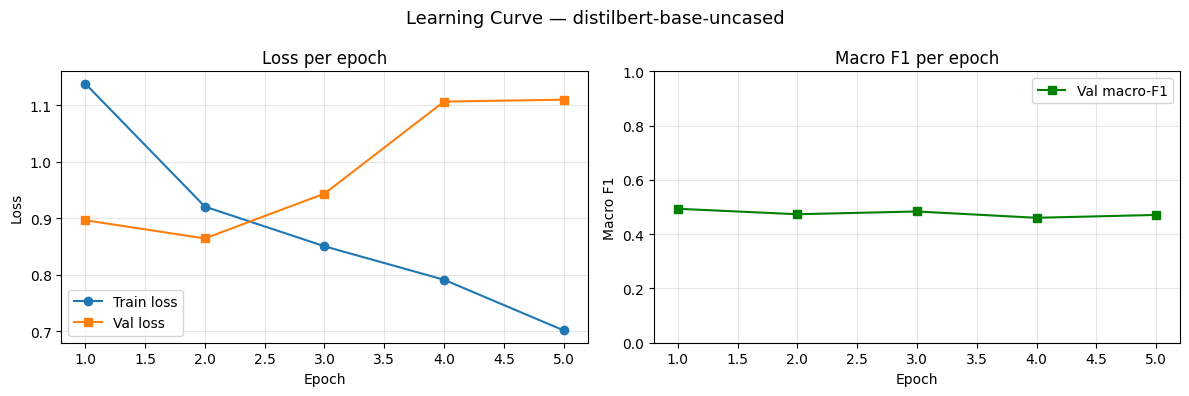

Saved: distilbert-base-uncased_learning_curve.png



=== distilbert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.864     0.452     0.594       168
   Interpret      0.869     0.921     0.894      1131
      Reveal      0.808     0.887     0.846       670
      Revise      0.000     0.000     0.000        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.847      2022
   macro avg      0.508     0.452     0.467      2022
weighted avg      0.826     0.847     0.830      2022


=== distilbert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              76              57           35            0   
true_Interpret              1            1042           88            0   
true_Reveal                11              65          594            0   
true_Revise                 0              29           16            0   
true_Inquire   

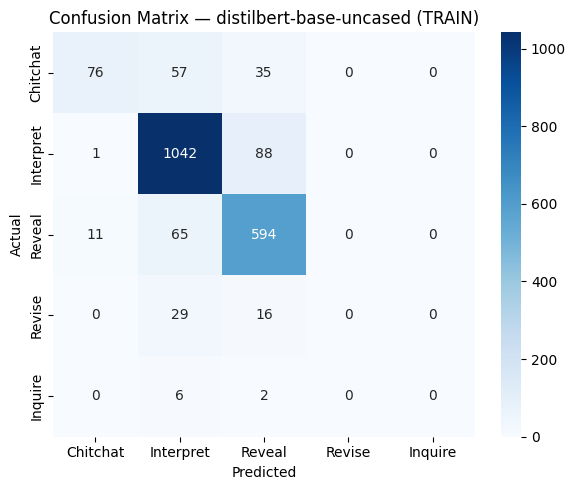


=== distilbert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.828     0.667     0.738        36
   Interpret      0.881     0.905     0.893       304
      Reveal      0.807     0.869     0.837       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.852       522
   macro avg      0.503     0.488     0.494       522
weighted avg      0.830     0.852     0.840       522


=== distilbert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              24               9            3            0   
true_Interpret              3             275           26            0   
true_Reveal                 2              20          146            0   
true_Revise                 0               5            5            0   
true_Inquire       

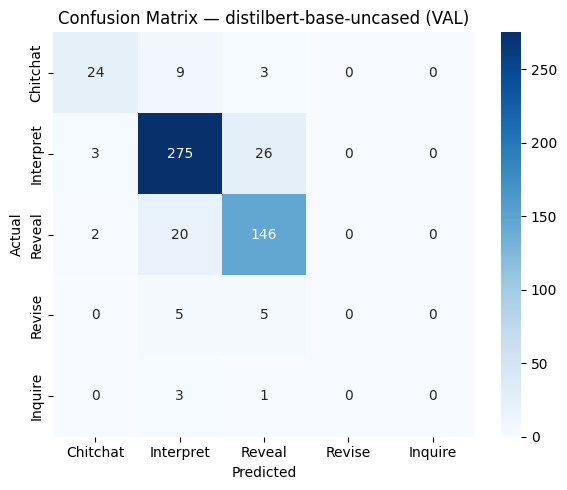


=== distilbert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,26
1,Reveal,Interpret,20
2,Chitchat,Interpret,9
3,Revise,Interpret,5
4,Revise,Reveal,5
5,Chitchat,Reveal,3
6,Inquire,Interpret,3
7,Interpret,Chitchat,3
8,Reveal,Chitchat,2
9,Inquire,Reveal,1



=== distilbert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
2,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
13,"USER: I want some magic kits, or tutorials.\nS...",Interpret,Reveal
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
18,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
19,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
21,"USER: hi,I want a phone\nSYSTEM: What size of ...",Interpret,Reveal
31,USER: hello!\nSYSTEM: hi\nUSER: I wanna a phot...,Interpret,Reveal



=== distilbert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.923     0.562     0.699        64
   Interpret      0.877     0.886     0.882       378
      Reveal      0.727     0.870     0.792       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.827       652
   macro avg      0.505     0.464     0.475       652
weighted avg      0.814     0.827     0.814       652


=== distilbert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              36              15           13            0   
true_Interpret              0             335           43            0   
true_Reveal                 3              22          168            0   
true_Revise                 0               8            4            0   
true_Inquire     

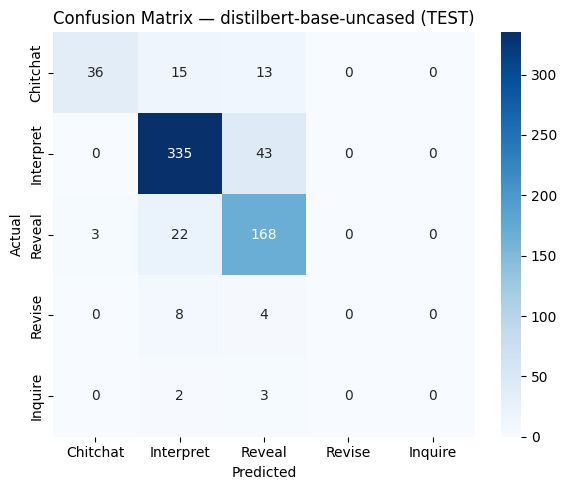


=== distilbert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Reveal,43
1,Reveal,Interpret,22
2,Chitchat,Interpret,15
3,Chitchat,Reveal,13
4,Revise,Interpret,8
5,Revise,Reveal,4
6,Inquire,Reveal,3
7,Reveal,Chitchat,3
8,Inquire,Interpret,2



=== distilbert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
39,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
40,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret


In [15]:
distilbert_trainer = run_model("distilbert-base-uncased", num_epochs=5)

## RoBERTa-base


  MODEL: roberta-base


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

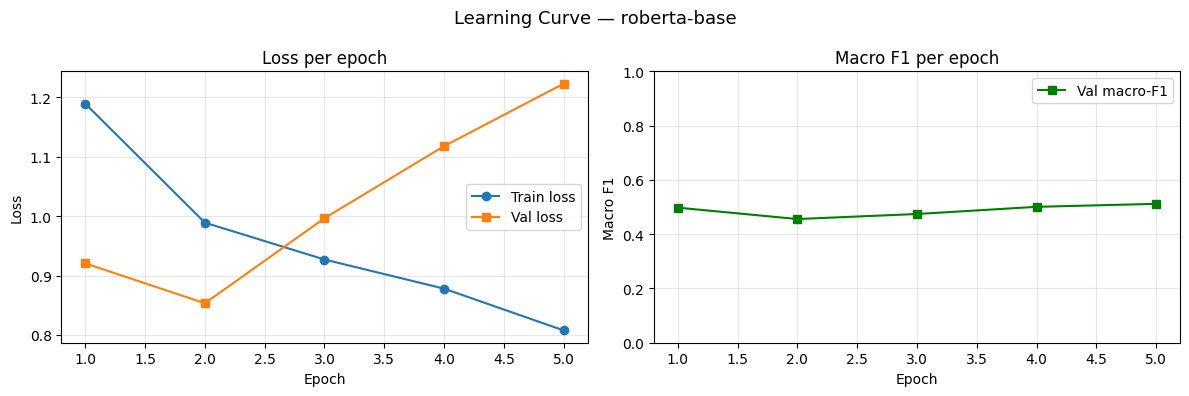

Saved: roberta-base_learning_curve.png



=== roberta-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.729     0.786     0.756       168
   Interpret      0.954     0.962     0.958      1131
      Reveal      0.942     0.942     0.942       670
      Revise      0.467     0.311     0.373        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.922      2022
   macro avg      0.618     0.600     0.606      2022
weighted avg      0.916     0.922     0.919      2022


=== roberta-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat             132              16           17            3   
true_Interpret             18            1088           15           10   
true_Reveal                21              15          631            3   
true_Revise                 7              19            5           14   
true_Inquire                3        

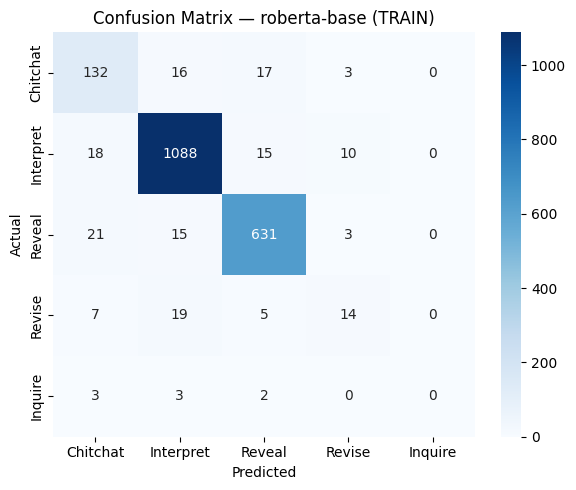


=== roberta-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.587     0.750     0.659        36
   Interpret      0.864     0.898     0.881       304
      Reveal      0.880     0.827     0.853       168
      Revise      0.500     0.100     0.167        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.843       522
   macro avg      0.566     0.515     0.512       522
weighted avg      0.836     0.843     0.836       522


=== roberta-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              27               8            1            0   
true_Interpret             15             273           15            1   
true_Reveal                 4              25          139            0   
true_Revise                 0               7            2            1   
true_Inquire                0            

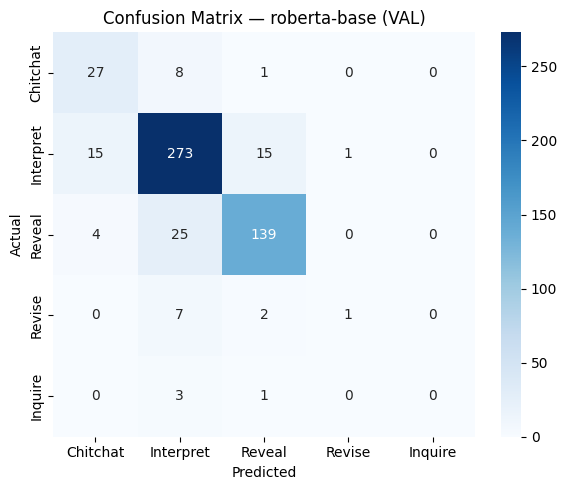


=== roberta-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,25
1,Interpret,Chitchat,15
2,Interpret,Reveal,15
3,Chitchat,Interpret,8
4,Revise,Interpret,7
5,Reveal,Chitchat,4
6,Inquire,Interpret,3
7,Revise,Reveal,2
8,Chitchat,Reveal,1
9,Interpret,Revise,1



=== roberta-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Chitchat
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
18,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Reveal
19,USER: I want a Collapsible Water Bottle\nSYSTE...,Interpret,Chitchat
21,"USER: hi,I want a phone\nSYSTEM: What size of ...",Interpret,Reveal
22,"USER: hi,I want a phone\nSYSTEM: What size of ...",Interpret,Reveal



=== roberta-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.731     0.594     0.655        64
   Interpret      0.884     0.910     0.897       378
      Reveal      0.819     0.865     0.841       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.842       652
   macro avg      0.487     0.474     0.479       652
weighted avg      0.827     0.842     0.833       652


=== roberta-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              38              12           14            0   
true_Interpret             11             344           19            4   
true_Reveal                 3              22          167            1   
true_Revise                 0              10            2            0   
true_Inquire                0          

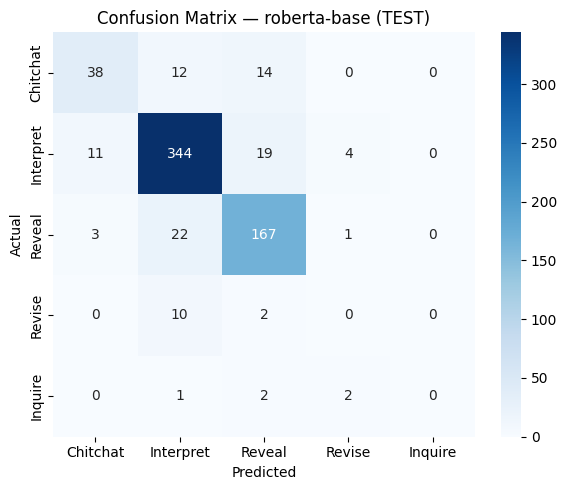


=== roberta-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,22
1,Interpret,Reveal,19
2,Chitchat,Reveal,14
3,Chitchat,Interpret,12
4,Interpret,Chitchat,11
5,Revise,Interpret,10
6,Interpret,Revise,4
7,Reveal,Chitchat,3
8,Inquire,Reveal,2
9,Revise,Reveal,2



=== roberta-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
39,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
40,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
41,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
43,USER: I want to buy a book of classical litera...,Reveal,Interpret


In [16]:
roberta_trainer = run_model("roberta-base", num_epochs=5)

## BERT-base-uncased


  MODEL: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

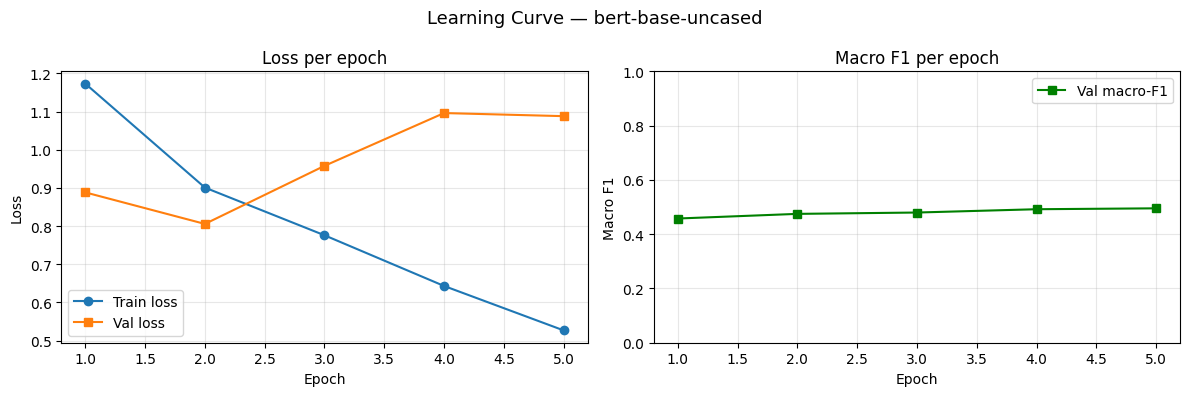

Saved: bert-base-uncased_learning_curve.png



=== bert-base-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.891     0.875     0.883       168
   Interpret      0.977     0.992     0.985      1131
      Reveal      0.957     0.961     0.959       670
      Revise      0.806     0.644     0.716        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.960      2022
   macro avg      0.726     0.695     0.709      2022
weighted avg      0.956     0.960     0.958      2022


=== bert-base-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat             147               5           15            1   
true_Interpret              5            1122            4            0   
true_Reveal                12              12          644            2   
true_Revise                 1               7            8           29   
true_Inquire               

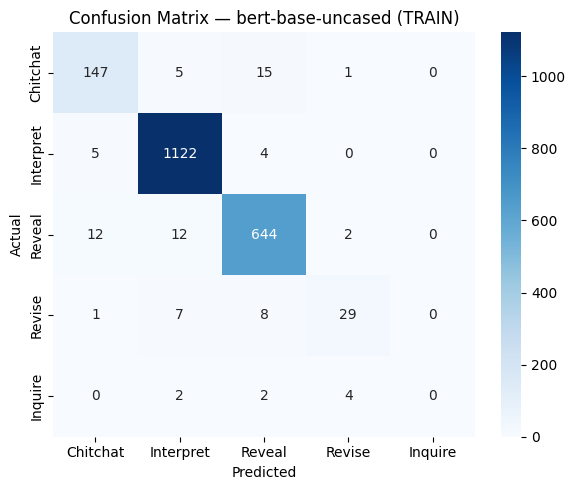


=== bert-base-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.675     0.750     0.711        36
   Interpret      0.862     0.944     0.901       304
      Reveal      0.919     0.815     0.864       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.864       522
   macro avg      0.491     0.502     0.495       522
weighted avg      0.844     0.864     0.852       522


=== bert-base-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              27               9            0            0   
true_Interpret              8             287            9            0   
true_Reveal                 5              26          137            0   
true_Revise                 0               8            2            0   
true_Inquire                0  

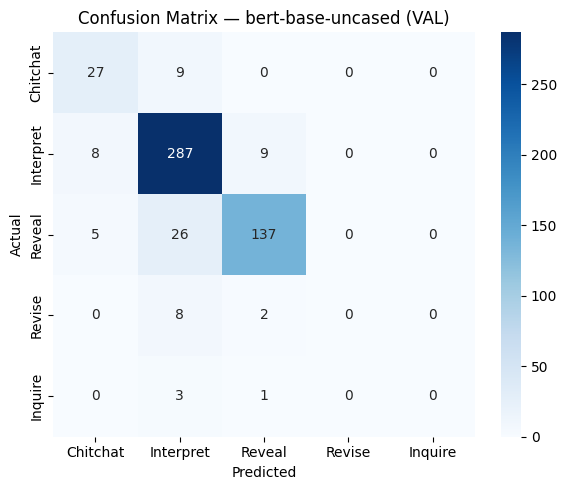


=== bert-base-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,26
1,Chitchat,Interpret,9
2,Interpret,Reveal,9
3,Revise,Interpret,8
4,Interpret,Chitchat,8
5,Reveal,Chitchat,5
6,Inquire,Interpret,3
7,Revise,Reveal,2
8,Inquire,Reveal,1



=== bert-base-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
32,USER: hello!\nSYSTEM: hi\nUSER: I wanna a phot...,Interpret,Chitchat
37,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat



=== bert-base-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.788     0.641     0.707        64
   Interpret      0.892     0.937     0.914       378
      Reveal      0.832     0.870     0.851       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.863       652
   macro avg      0.502     0.490     0.494       652
weighted avg      0.841     0.863     0.851       652


=== bert-base-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              41              11           12            0   
true_Interpret              6             354           17            1   
true_Reveal                 5              20          168            0   
true_Revise                 0               9            3            0   
true_Inquire                0

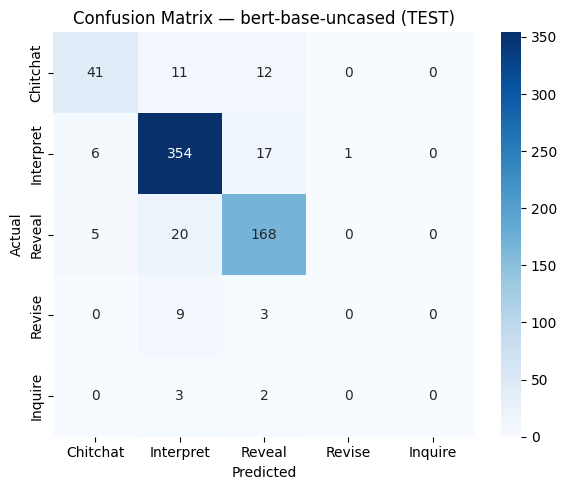


=== bert-base-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,20
1,Interpret,Reveal,17
2,Chitchat,Reveal,12
3,Chitchat,Interpret,11
4,Revise,Interpret,9
5,Interpret,Chitchat,6
6,Reveal,Chitchat,5
7,Inquire,Interpret,3
8,Revise,Reveal,3
9,Inquire,Reveal,2



=== bert-base-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Reveal
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
39,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret
40,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret


In [17]:
bert_trainer = run_model("bert-base-uncased", num_epochs=5)

## MiniLM


  MODEL: microsoft/MiniLM-L12-H384-uncased


config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNorm.weight', 'bert.encoder.layer.2.attention.output.LayerNorm.bias', 'bert.encoder.layer.2.output.LayerNorm.weight', 'bert.encoder.layer.2.output.LayerNorm.bias', 'bert.encoder.layer.3.attention.output.LayerNorm.weight', 'bert.encoder.layer.3.attention.output.LayerNorm.bias', 'bert.encoder.layer.3.output.LayerNorm.weight', 'bert.encoder.layer.3.output.LayerNorm.bias', 'bert.encoder.layer.4.attention.output.La

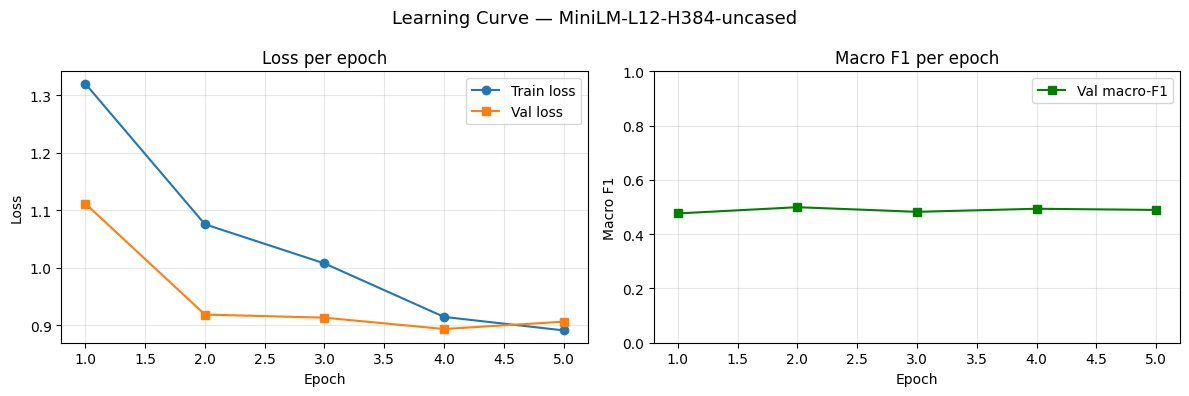

Saved: minilm-l12-h384-uncased_learning_curve.png



=== MiniLM-L12-H384-uncased — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.916     0.452     0.606       168
   Interpret      0.817     0.985     0.893      1131
      Reveal      0.929     0.799     0.859       670
      Revise      0.000     0.000     0.000        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.853      2022
   macro avg      0.532     0.447     0.472      2022
weighted avg      0.841     0.853     0.835      2022


=== MiniLM-L12-H384-uncased — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              76              73           19            0   
true_Interpret              1            1114           16            0   
true_Reveal                 6             129          535            0   
true_Revise                 0              40            5            0   
true_Inquire   

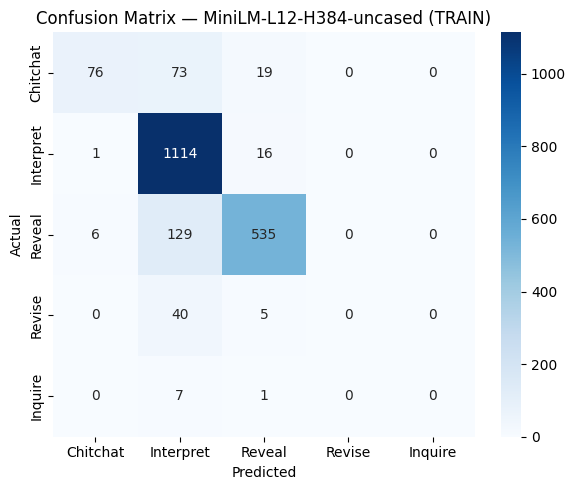


=== MiniLM-L12-H384-uncased — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.857     0.667     0.750        36
   Interpret      0.831     0.974     0.897       304
      Reveal      0.942     0.774     0.850       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.862       522
   macro avg      0.526     0.483     0.499       522
weighted avg      0.847     0.862     0.848       522


=== MiniLM-L12-H384-uncased — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              24              11            1            0   
true_Interpret              3             296            5            0   
true_Reveal                 1              37          130            0   
true_Revise                 0               9            1            0   
true_Inquire       

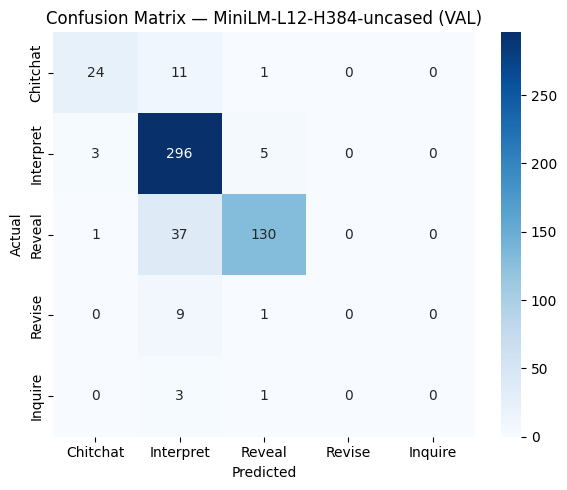


=== MiniLM-L12-H384-uncased VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,37
1,Chitchat,Interpret,11
2,Revise,Interpret,9
3,Interpret,Reveal,5
4,Interpret,Chitchat,3
5,Inquire,Interpret,3
6,Chitchat,Reveal,1
7,Inquire,Reveal,1
8,Reveal,Chitchat,1
9,Revise,Reveal,1



=== MiniLM-L12-H384-uncased VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Reveal
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Reveal
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Interpret
14,"USER: Show me some stylish, lightweight Compac...",Interpret,Reveal
15,"USER: Show me some stylish, lightweight Compac...",Reveal,Interpret
38,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
39,USER: I want a school bag.\nSYSTEM: Do you hav...,Reveal,Interpret
40,USER: hi!,Interpret,Chitchat
46,USER: GOOD afternoone\nSYSTEM: GOOD afternoone...,Reveal,Interpret



=== MiniLM-L12-H384-uncased — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.971     0.531     0.687        64
   Interpret      0.836     0.960     0.894       378
      Reveal      0.858     0.813     0.835       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.850       652
   macro avg      0.533     0.461     0.483       652
weighted avg      0.834     0.850     0.833       652


=== MiniLM-L12-H384-uncased — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              34              23            7            0   
true_Interpret              0             363           15            0   
true_Reveal                 1              35          157            0   
true_Revise                 0              10            2            0   
true_Inquire     

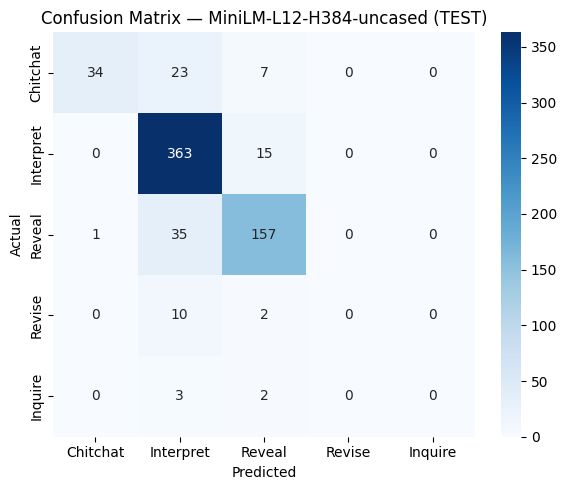


=== MiniLM-L12-H384-uncased TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Reveal,Interpret,35
1,Chitchat,Interpret,23
2,Interpret,Reveal,15
3,Revise,Interpret,10
4,Chitchat,Reveal,7
5,Inquire,Interpret,3
6,Inquire,Reveal,2
7,Revise,Reveal,2
8,Reveal,Chitchat,1



=== MiniLM-L12-H384-uncased TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Interpret
11,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Interpret
13,USER: I want to buy a school bag\nSYSTEM: what...,Reveal,Interpret
14,USER: I want to buy a school bag\nSYSTEM: what...,Chitchat,Interpret
20,"USER: I want to buy a lightweight laptop, main...",Revise,Reveal
22,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
23,"USER: I want to buy a lightweight laptop, main...",Revise,Interpret
27,"USER: I’m looking for a smartwatch for kids, w...",Revise,Interpret
38,USER: Please recommend me a baby stroller\nSYS...,Reveal,Interpret


In [18]:
minilm_trainer = run_model("microsoft/MiniLM-L12-H384-uncased", num_epochs=5)

## DeBERTa-v3-base

> **Note:** Run the cell below before this model if sentencepiece is not installed.
> ```
> !pip install sentencepiece -q
> ```

In [19]:
!pip install sentencepiece -q



  MODEL: microsoft/deberta-v3-base


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

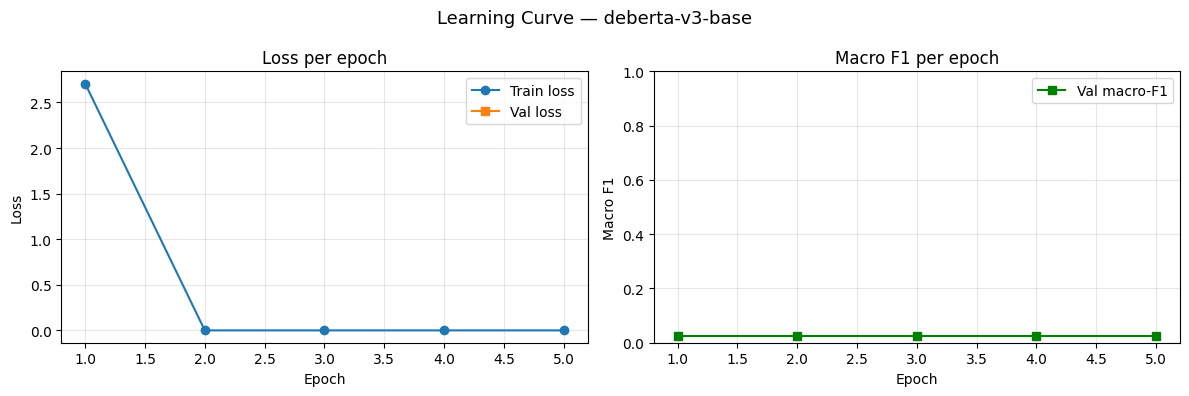

Saved: deberta-v3-base_learning_curve.png



=== deberta-v3-base — TRAIN CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.083     1.000     0.153       168
   Interpret      0.000     0.000     0.000      1131
      Reveal      0.000     0.000     0.000       670
      Revise      0.000     0.000     0.000        45
     Inquire      0.000     0.000     0.000         8

    accuracy                          0.083      2022
   macro avg      0.017     0.200     0.031      2022
weighted avg      0.007     0.083     0.013      2022


=== deberta-v3-base — TRAIN CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat             168               0            0            0   
true_Interpret           1131               0            0            0   
true_Reveal               670               0            0            0   
true_Revise                45               0            0            0   
true_Inquire                8  

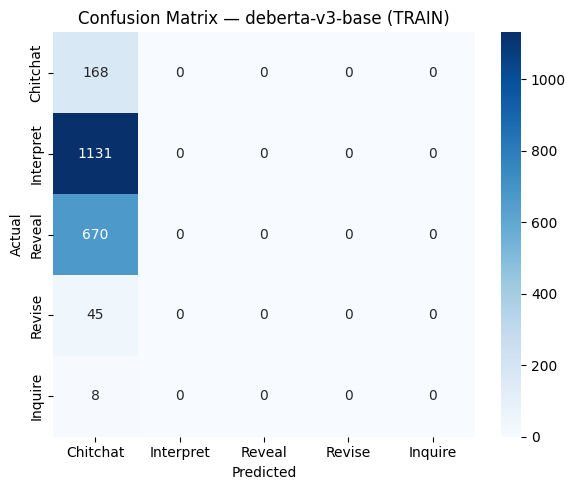


=== deberta-v3-base — VAL CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.069     1.000     0.129        36
   Interpret      0.000     0.000     0.000       304
      Reveal      0.000     0.000     0.000       168
      Revise      0.000     0.000     0.000        10
     Inquire      0.000     0.000     0.000         4

    accuracy                          0.069       522
   macro avg      0.014     0.200     0.026       522
weighted avg      0.005     0.069     0.009       522


=== deberta-v3-base — VAL CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              36               0            0            0   
true_Interpret            304               0            0            0   
true_Reveal               168               0            0            0   
true_Revise                10               0            0            0   
true_Inquire                4      

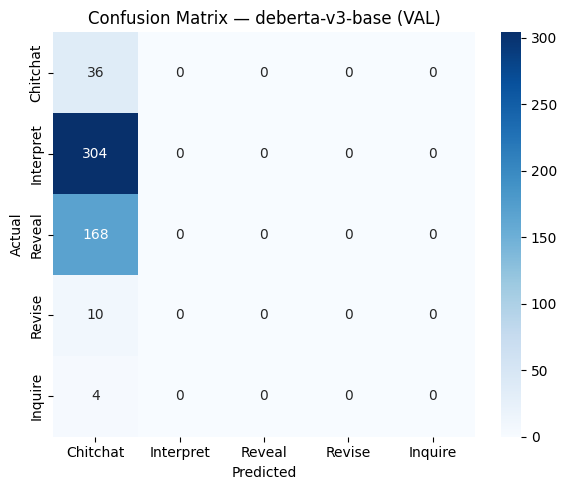


=== deberta-v3-base VAL TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Chitchat,304
1,Reveal,Chitchat,168
2,Revise,Chitchat,10
3,Inquire,Chitchat,4



=== deberta-v3-base VAL SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
1,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a plane.,Interpret,Chitchat
2,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Chitchat
3,USER: hi!\nSYSTEM: Hello.\nUSER: I wanna a pla...,Interpret,Chitchat
4,USER: I want to buy a bicycle,Reveal,Chitchat
5,USER: I want to buy a bicycle\nSYSTEM: How abo...,Revise,Chitchat
6,USER: I want to buy a bicycle\nSYSTEM: How abo...,Interpret,Chitchat
7,USER: I want Cotton socks,Reveal,Chitchat
8,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
9,USER: I want Cotton socks\nSYSTEM: Is this pla...,Reveal,Chitchat
10,USER: I want to buy some acne treatment ointme...,Reveal,Chitchat



=== deberta-v3-base — TEST CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

    Chitchat      0.098     1.000     0.179        64
   Interpret      0.000     0.000     0.000       378
      Reveal      0.000     0.000     0.000       193
      Revise      0.000     0.000     0.000        12
     Inquire      0.000     0.000     0.000         5

    accuracy                          0.098       652
   macro avg      0.020     0.200     0.036       652
weighted avg      0.010     0.098     0.018       652


=== deberta-v3-base — TEST CONFUSION MATRIX ===
                pred_Chitchat  pred_Interpret  pred_Reveal  pred_Revise  \
true_Chitchat              64               0            0            0   
true_Interpret            378               0            0            0   
true_Reveal               193               0            0            0   
true_Revise                12               0            0            0   
true_Inquire                5    

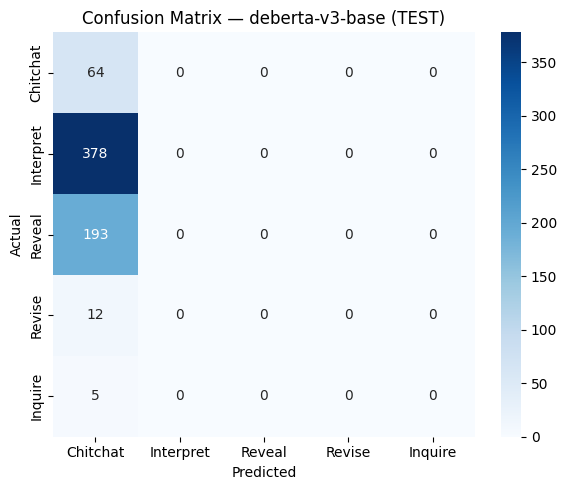


=== deberta-v3-base TEST TOP CONFUSED PAIRS ===


,true_label,predicted_label,count
0,Interpret,Chitchat,378
1,Reveal,Chitchat,193
2,Revise,Chitchat,12
3,Inquire,Chitchat,5



=== deberta-v3-base TEST SAMPLE MISCLASSIFIED EXAMPLES ===


,text,true_label,predicted_label
0,USER: I want a model airplane,Reveal,Chitchat
1,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
2,"USER: I want a model airplane\nSYSTEM: Okay, t...",Reveal,Chitchat
4,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle!!,Reveal,Chitchat
5,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle...,Interpret,Chitchat
6,USER: hi!\nSYSTEM: hi\nUSER: I wanna a bicycle...,Interpret,Chitchat
7,USER: I want to buy an electronic lock,Reveal,Chitchat
8,USER: I want to buy an electronic lock\nSYSTEM...,Interpret,Chitchat
9,USER: I want a cotton slippers.,Reveal,Chitchat
10,USER: I want a cotton slippers.\nSYSTEM: do yo...,Reveal,Chitchat


In [20]:
deberta_trainer = run_model("microsoft/deberta-v3-base", num_epochs=5)